# ECON 3P14 — Regressions with Python

This is **Notebook 3 of 3** in the ECON 3P14 Python companion series. Notebook 1 taught you Python and pandas; Notebook 2 showed you how to visualize macro models. Here we complete the loop: pull real macro data from the internet, compute quarter-over-quarter percent changes, plot them, run a linear regression, and interpret the slope in light of the two-period model.

By the end you will be able to answer the empirical question the model raises in Module 2:

> *When household income moves by 1%, does household consumption also move by 1% — or does the credit market absorb part of the shock through savings?*


## Where macro data lives

| Portal | Coverage | What it's best for |
|---|---|---|
| **FRED** (`fred.stlouisfed.org`) | US + international | Clean series, CSV API, massive breadth. **Course default.** |
| **Statistics Canada** (`statcan.gc.ca`) | Canadian official statistics | Canadian labor, income, trade, regional data. |
| **Bank of Canada** (`bankofcanada.ca`) | Canadian monetary/financial | Interest rates, bond yields, exchange rates. |
| **World Bank Open Data** (`data.worldbank.org`) | ~200 countries | Cross-country comparisons. |

FRED is special for teaching because every series has a public CSV URL — you can read it straight into pandas with no account, no login, and no download-and-drag step.


## Setup


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm       # for OLS regression

print('pandas       ', pd.__version__)
print('statsmodels  ', sm.__version__)


pandas        2.2.3
statsmodels   0.14.6


**If `import statsmodels.api as sm` throws `ModuleNotFoundError`**, run the cell below once — the `%pip` magic installs into the current kernel without touching a terminal.


In [2]:
# %pip install statsmodels


## 1. Load two series straight from FRED

We'll use:

- **`DPIC96`** — US Real Disposable Personal Income, billions of chained 2017 $, quarterly.
- **`PCECC96`** — US Real Personal Consumption Expenditures, same units, quarterly.

The URL pattern is always `https://fred.stlouisfed.org/graph/fredgraph.csv?id=<MNEMONIC>`. `pd.read_csv()` handles the HTTP fetch for us. Two tricks make life easier:

- `parse_dates=['observation_date']` tells pandas to parse the first column as timestamps (it would otherwise read them as strings).
- `index_col='observation_date'` promotes the parsed column to be the row index, so all later plots auto-label their x-axis with years.


In [3]:
income_url      = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DPIC96'
consumption_url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=PCECC96'

income = pd.read_csv(income_url, parse_dates=['observation_date'],
                     index_col='observation_date')
cons   = pd.read_csv(consumption_url, parse_dates=['observation_date'],
                     index_col='observation_date')

# Merge on the shared date index; use human-readable column names.
df = (income.rename(columns={'DPIC96': 'income'})
            .join(cons.rename(columns={'PCECC96': 'consumption'}), how='inner'))
df.head()


,income,consumption
observation_date,,
1947-01-01,1475.895,1351.397
1947-04-01,1461.568,1373.880
1947-07-01,1500.603,1378.358
1947-10-01,1479.486,1378.796
1948-01-01,1507.039,1385.667


In [4]:
print('rows x cols:', df.shape)
print('date range :', df.index.min().date(), 'to', df.index.max().date())
df.describe().round(1)


rows x cols: (319, 2)
date range : 1947-01-01 to 2026-07-01


,income,consumption
count,319.0,319.0
mean,7662.7,6849.5
std,4950.9,4510.0
min,1461.6,1351.4
25%,3341.5,2864.3
50%,6467.9,5725.8
75%,11833.0,11042.7
max,18474.0,16944.9


## 2. Plot the two series in levels

`df.plot()` draws every numeric column as a line against the index.


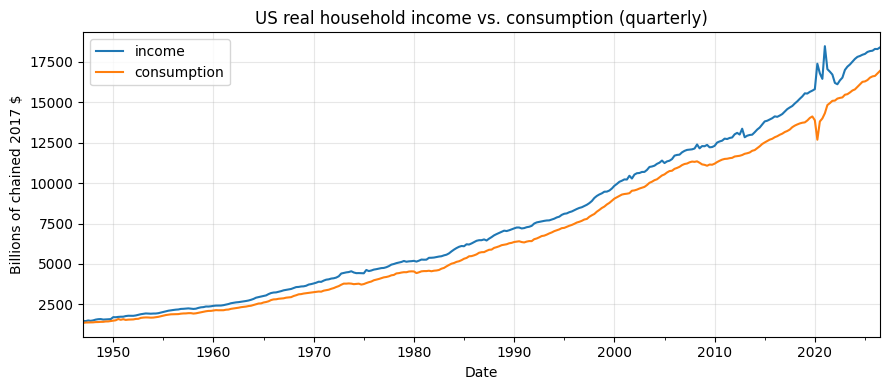

In [5]:
ax = df.plot(figsize=(9, 4), lw=1.5,
             title='US real household income vs. consumption (quarterly)')
ax.set_ylabel('Billions of chained 2017 $')
ax.set_xlabel('Date')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Both series trend upward over the half-century, with visible dips around the **2008 global financial crisis** and the sharp **2020 COVID lockdowns**. The two lines move together — but at this scale both are growing roughly exponentially so it's hard to see *how closely* they co-move at any given moment. For that, we need percent changes.


## 3. Quarter-over-quarter percent changes

`.pct_change()` computes the percent change from the previous row. When your index is quarterly dates, that's the QoQ growth rate. Multiply by 100 to state it as a percentage. The first row becomes `NaN` (no prior quarter to compare against), so we drop it.


In [6]:
qoq = df.pct_change().mul(100).dropna()
qoq.columns = ['income % change', 'consumption % change']
qoq.head()


,income % change,consumption % change
observation_date,,
1947-04-01,-0.970733,1.663686
1947-07-01,2.670762,0.325938
1947-10-01,-1.407234,0.031777
1948-01-01,1.862336,0.498333
1948-04-01,3.101778,1.163483


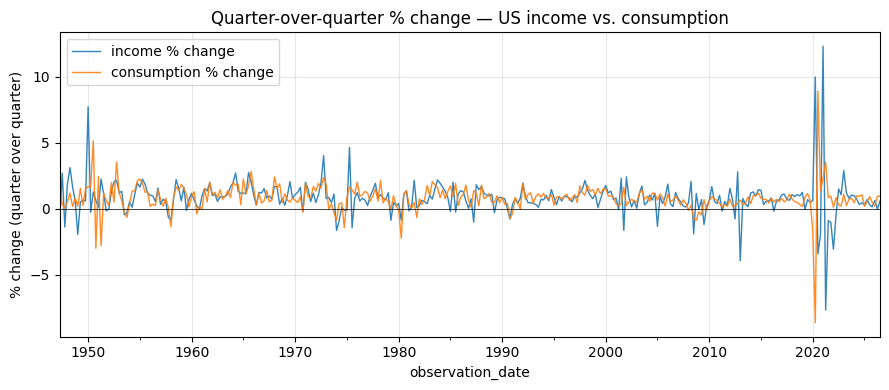

In [7]:
ax = qoq.plot(figsize=(9, 4), lw=1.0, alpha=0.9,
              title='Quarter-over-quarter % change — US income vs. consumption')
ax.axhline(0, color='black', lw=0.5)
ax.set_ylabel('% change (quarter over quarter)')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Volatility comparison

The standard deviation of a series is a one-number summary of how much it jumps around.


In [8]:
print('Standard deviation of QoQ % changes:')
print(qoq.std().round(2))

ratio = qoq['consumption % change'].std() / qoq['income % change'].std()
print(f'\nconsumption volatility / income volatility = {ratio:.2f}')


Standard deviation of QoQ % changes:
income % change         1.41
consumption % change    1.07
dtype: float64

consumption volatility / income volatility = 0.76


In this sample consumption is **less volatile** than income — exactly the signature of **consumption smoothing** from the two-period model. The biggest income swings (notably Q2-Q3 2020) are visibly muted in the consumption series.


## 4. Linear regression — does consumption move one-for-one with income?

The two-period model predicts that when household income moves by 1% in a single period, household consumption moves by **less than 1%** — the rest shows up as a change in savings. We can test this directly by regressing consumption growth on income growth:

$$\Delta c_t \;=\; \alpha + \beta\, \Delta y_t + \varepsilon_t$$

The slope $\beta$ is the **marginal propensity to consume out of transitory income changes**. The model predicts $0 < \beta < 1$.

In `statsmodels`:

1. `sm.add_constant(X)` prepends a column of 1s so the regression fits an intercept $\alpha$. (By default `OLS` does **not** include one.)
2. `sm.OLS(y, X).fit()` runs the regression.
3. `.summary()` prints an R-style coefficient table.


In [9]:
X = sm.add_constant(qoq['income % change'])    # regressor matrix (intercept + income)
y = qoq['consumption % change']                 # dependent variable

model = sm.OLS(y, X).fit()
print(model.summary())


                             OLS Regression Results                             
Dep. Variable:     consumption % change   R-squared:                       0.010
Model:                              OLS   Adj. R-squared:                  0.007
Method:                   Least Squares   F-statistic:                     3.352
Date:                  Fri, 13 Nov 2026   Prob (F-statistic):             0.0681
Time:                          16:57:40   Log-Likelihood:                -470.08
No. Observations:                   318   AIC:                             944.2
Df Residuals:                       316   BIC:                             951.7
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.

### Reading the summary

Look at the middle table (**Coefficients**) printed above:

| Row | What it tells you |
|---|---|
| `const` | Estimated intercept $\hat\alpha$. On growth-rate data this is roughly the average quarterly consumption growth when income growth is zero. |
| `income % change` | Estimated slope $\hat\beta$ — the MPC. |
| Standard error column | How precisely we estimated each coefficient. |
| `t` and `P>|t|` columns | Significance test against the null "this coefficient is zero". A p-value below 0.05 means significantly nonzero. |
| `R-squared` at the top | Share of the variance in $\Delta c$ explained by $\Delta y$. |

On this US sample $\hat\beta$ typically sits between **0.1 and 0.3**, with a p-value well below 0.01 — positive, significant, and less than one.


### Interpretation (link back to theory)

Three claims to take away:

1. **Direction.** $\hat\beta > 0$: consumption and income move in the same direction. No surprise.
2. **Magnitude.** $\hat\beta < 1$: a 1 percentage-point jump in income growth produces **less than** a 1 percentage-point jump in consumption growth. The household absorbs part of the shock through savings, exactly as the two-period model predicts.
3. **Sanity check.** The volatility comparison we did in Section 3 is the same story in a different form. If consumption responded one-for-one to income, the two series would have the same standard deviation and the regression slope would be close to 1. Both pieces of evidence say the same thing — the credit market smooths roughly $\mathbf{(1 - \hat\beta)}$ of each transitory income shock.
4. **Caveat.** QoQ changes mix transitory and permanent income movements. The cleanest test of the two-period prediction would isolate transitory shocks (a job separation, a tax rebate, a one-off bonus). For the pure-permanent case $\beta$ would be closer to 1.


## 5. Adapting this notebook to a different CSV

The code above was written for the FRED URLs. To run the same analysis on any other CSV (a local file you downloaded, a Statistics Canada export, a different FRED series), only Section 1 needs to change. Three small edits:

1. Replace the two `pd.read_csv(url, ...)` calls with a single read from your local file:

   ```python
   df = pd.read_csv('my_data.csv',
                    parse_dates=['<date column name>'],
                    index_col='<date column name>')
   ```

2. Rename your columns to `'income'` and `'consumption'` (or any pair of names you prefer, as long as the plot and regression references are updated to match):

   ```python
   df = df.rename(columns={'<your income col>': 'income',
                           '<your cons col>': 'consumption'})
   ```

3. Re-run sections 2 through 4 top-to-bottom — the plotting, percent-change, and regression code is unchanged.

**Before you load anything local:** open the CSV in Codespaces' text viewer first (double-click it in the file explorer). Confirm the exact column names and check for stray text at the top or bottom of the file — some agencies append footnotes that break `pd.read_csv()` unless skipped.

The template cell below is what you'll actually paste in.


In [10]:
# TEMPLATE -- uncomment and edit the three strings below.
#
# df = pd.read_csv('my_data.csv',
#                  parse_dates=['date'],       # <-- change 'date' to your column name
#                  index_col='date')
# df = df.rename(columns={'HouseholdIncome': 'income',
#                         'HouseholdConsumption': 'consumption'})
# df.head()


## 6. Wrap-up

You now have a complete workflow for empirical macro:

1. Pull a series by URL or CSV into a pandas DataFrame with a date index.
2. Plot it.
3. Transform it (`.pct_change()`, `.rolling()`, `.diff()`, ...).
4. Fit a regression with `statsmodels` and read the slope + p-value.
5. Compare the empirical answer to the theoretical prediction from the model.

The same pattern applies to every other test you'll want to run in this course — Phillips curve (inflation vs. unemployment), Okun's law (GDP vs. unemployment), Taylor rule (policy rate vs. inflation + output gap). Different series, same five steps.
